In [ ]:
import pandas as pd
import math
from sklearn.metrics import mean_squared_error
import random
from datetime import datetime as dt
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.arima.model import ARIMA
from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, LSTM
from sklearn.metrics import mean_absolute_percentage_error, mean_squared_error
import yfinance as yf
import warnings
warnings.filterwarnings('ignore')

### For Stock (RELIANCE)


In [ ]:
stock_ticker = 'RELIANCE.NS'
df = pd.DataFrame(yf.download(stock_ticker, start='2015-01-01', end='2025-01-01'))

df.reset_index(inplace=True)
df = df[['Date', 'Close']]
df.rename(columns={'Date':'date', 'Close':'close'}, inplace=True)

[*********************100%***********************]  1 of 1 completed


In [ ]:
df2 = pd.DataFrame(np.log(df['close']))
df2['date'] = pd.to_datetime(df['date']).dt.date

df2.set_index('date', inplace=True)
df2.rename(columns={'RELIANCE.NS':'close'}, inplace=True)

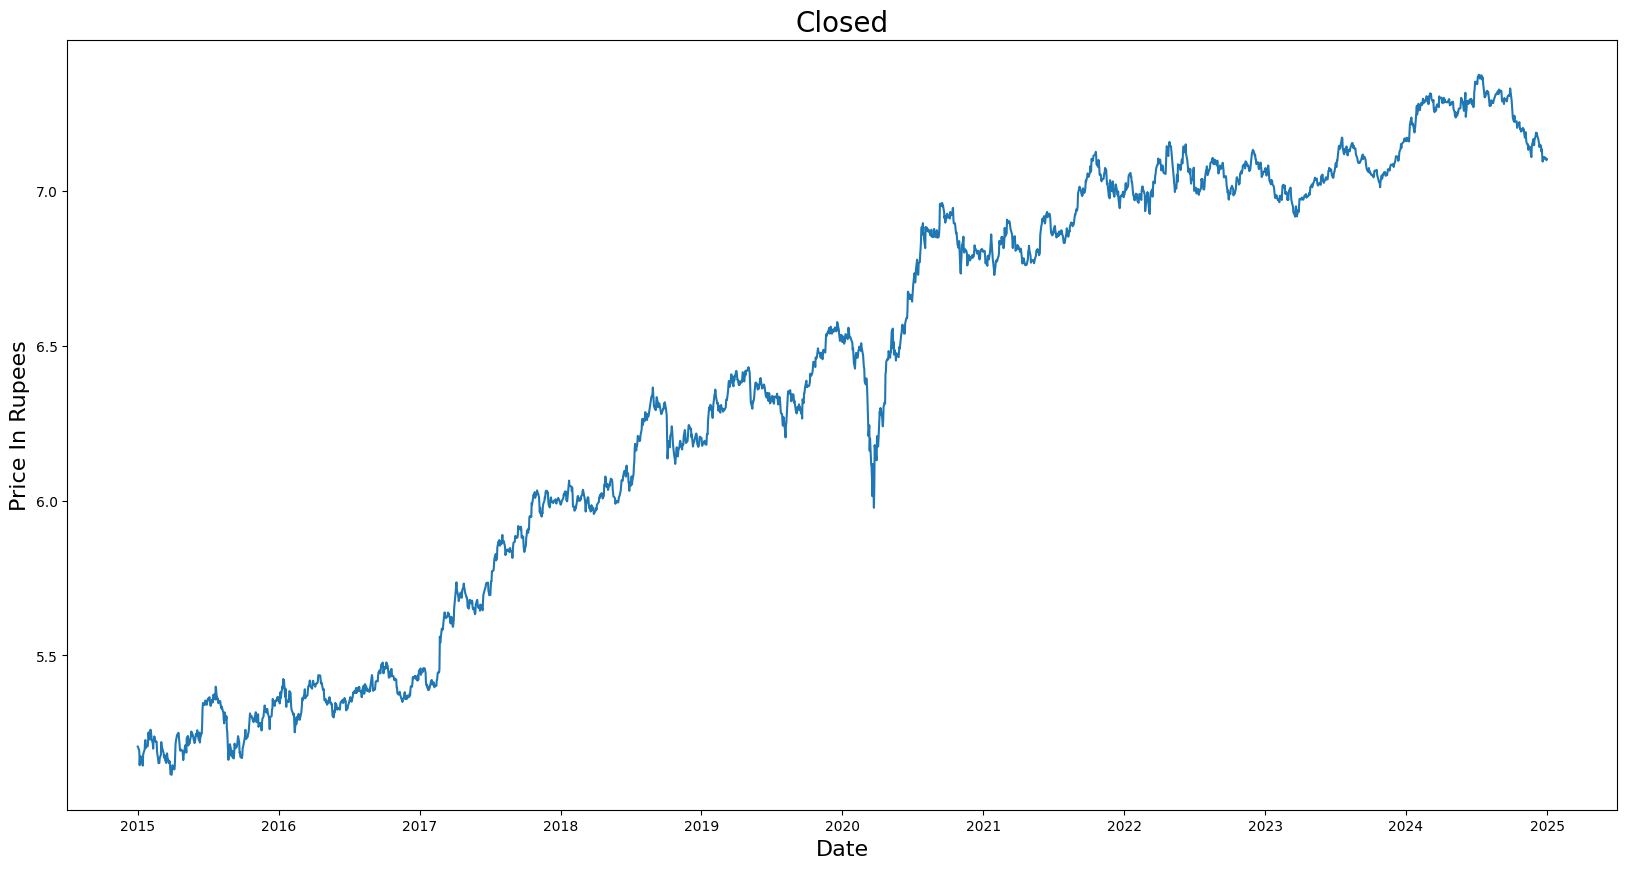

In [ ]:
plt.figure(figsize=(20,10))
plt.plot(df2['close'])
plt.title('Closed', fontsize=20)
plt.ylabel('Price In Rupees', fontsize=16)
plt.xlabel('Date', fontsize=16)
plt.show()

In [ ]:
def check_stationary(data):
    result = adfuller(data)
    print('ADF Statistic:', result[0])
    print('p-value:', result[1])
    if result[1] <= 0.05:
        print('The data is stationary.')
    else:
        print('The data is not stationary.')

check_stationary(df2.close)

first_diffs = df2.close - df2.close.shift(1)

df2['FirstDifference'] = first_diffs
df2.dropna(inplace=True)

check_stationary(df2.FirstDifference)

ADF Statistic: -1.3875138079911427
p-value: 0.5882473017910611
The data is not stationary.
ADF Statistic: -15.013684241758288
p-value: 1.0465306348474681e-27
The data is stationary.


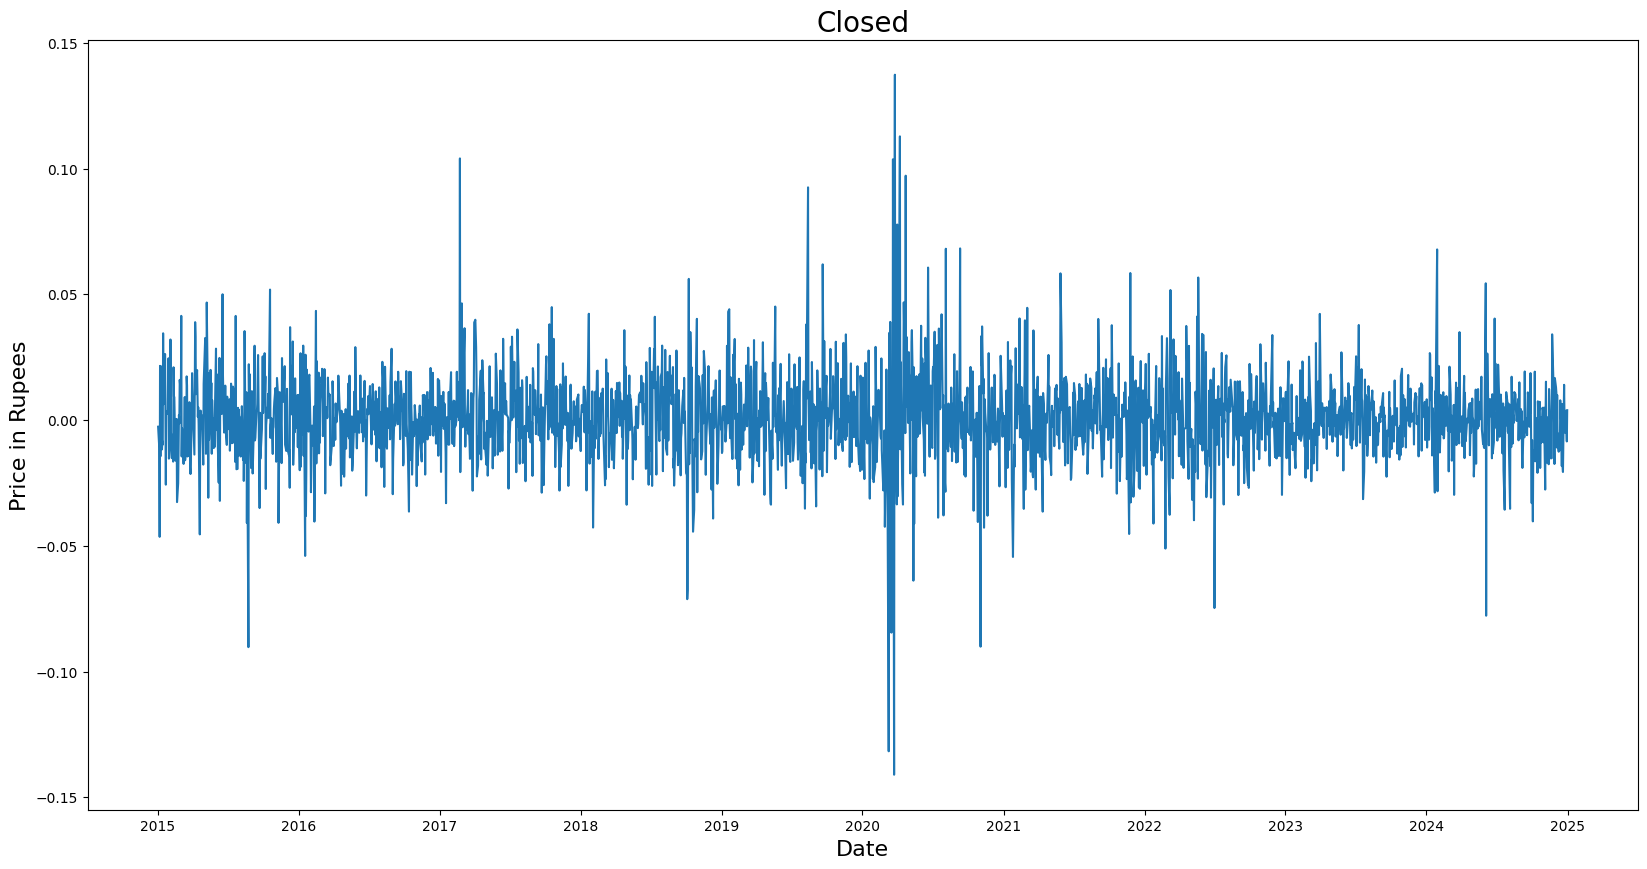

In [ ]:
plt.figure(figsize=(20,10))
plt.plot(df2.FirstDifference)
plt.title('Closed', fontsize=20)
plt.ylabel('Price in Rupees', fontsize=16)
plt.xlabel('Date', fontsize=16)
plt.show()

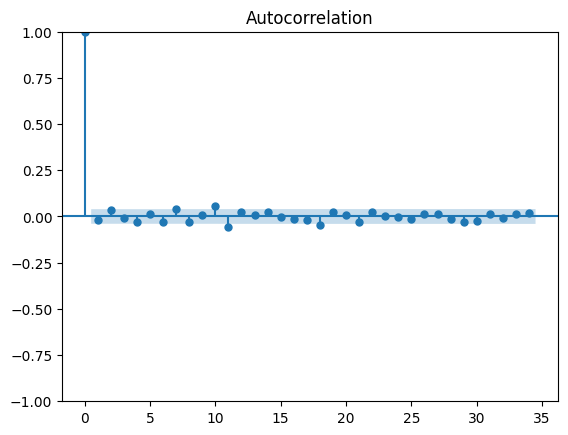

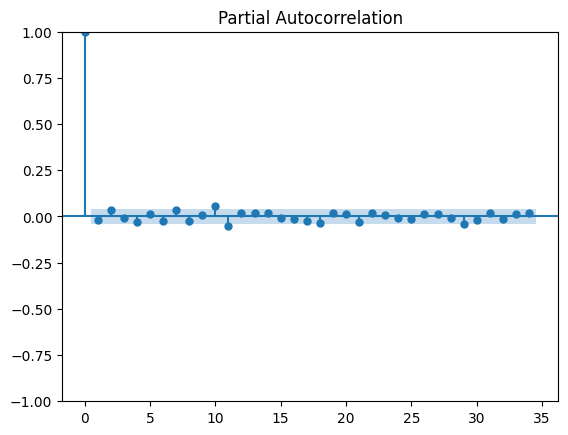

In [ ]:
# Plotting ACF plot to choose value for MA

plot_acf(df2.FirstDifference)
plt.show()

# Plotting PACF plot to choose value for AR

plot_pacf(df2.FirstDifference)
plt.show()

In [ ]:
# Creating the ARIMA model and fitting the values

model = ARIMA(df2.FirstDifference.dropna(), order=(1,1,0))
result = model.fit()

fvalues = result.fittedvalues
result.summary()

residual = result.resid
residual = residual.cumsum()

In [ ]:

a = df2.close - df2.FirstDifference
diff_results = residual + residual.shift(-1)
diff_results = diff_results + a

In [ ]:
df1 = diff_results
df1.dropna(inplace=True)

# Normalizing the data

scaler = MinMaxScaler(feature_range=(0,1))
df1 = scaler.fit_transform(np.array(df1).reshape(-1,1))

In [ ]:
# Defining the train and test data size

training_size=int(len(df1)*0.70)
test_size=len(df1)-training_size
train_data,test_data=df1[:training_size],df1[training_size:]

In [ ]:
def create_dataset(dataset, time_step=60):
	dataX, dataY = [], []
	for i in range(len(dataset)-time_step-1):
		a = dataset[i:(i+time_step)]
		dataX.append(a)
		dataY.append(dataset[i + time_step])
	return np.array(dataX), np.array(dataY)

time_step = 60
X_train, y_train = create_dataset(train_data, time_step)
X_test, y_test = create_dataset(test_data, time_step)

In [ ]:
X_train =X_train.reshape(X_train.shape[0],X_train.shape[1] , 1)
X_test = X_test.reshape(X_test.shape[0],X_test.shape[1] , 1)

len(X_train), len(y_train), len(X_test), len(y_test)

(1664, 1664, 679, 679)

In [ ]:
# Creating LSTM model

model=Sequential()
model.add(LSTM(64, input_shape=(X_train.shape[1],1)))
model.add(Dropout(0.3))
model.add(Dense(25))
model.add(Dense(1))
model.compile(loss='mean_squared_error',optimizer='adam', metrics=['accuracy'])

In [ ]:
# Summary for LSTM model

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                          │ (None, 64)                  │          16,896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 64)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 25)                  │           1,625 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 1)                   │              26 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 18,547 (72.45 KB)

 Trainable params: 18,547 (72.45 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
model.fit(X_train,y_train,validation_data=(X_test,y_test),epochs=5,batch_size=64,verbose=1)

Epoch 1/5
26/26 ━━━━━━━━━━━━━━━━━━━━ 10s 124ms/step - accuracy: 0.0000e+00 - loss: 0.0802 - val_accuracy: 0.0015 - val_loss: 0.0278
Epoch 2/5
26/26 ━━━━━━━━━━━━━━━━━━━━ 3s 45ms/step - accuracy: 0.0000e+00 - loss: 0.0069 - val_accuracy: 0.0015 - val_loss: 0.0023
Epoch 3/5
26/26 ━━━━━━━━━━━━━━━━━━━━ 1s 46ms/step - accuracy: 0.0000e+00 - loss: 0.0040 - val_accuracy: 0.0015 - val_loss: 1.7644e-04
Epoch 4/5
26/26 ━━━━━━━━━━━━━━━━━━━━ 1s 46ms/step - accuracy: 0.0000e+00 - loss: 0.0030 - val_accuracy: 0.0015 - val_loss: 1.7161e-04
Epoch 5/5
26/26 ━━━━━━━━━━━━━━━━━━━━ 1s 45ms/step - accuracy: 0.0000e+00 - loss: 0.0026 - val_accuracy: 0.0015 - val_loss: 5.7282e-04


In [ ]:
train_predict=model.predict(X_train)
test_predict=model.predict(X_test)

52/52 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step
22/22 ━━━━━━━━━━━━━━━━━━━━ 1s 27ms/step


In [ ]:
# Metrics
mape_stock = mean_absolute_percentage_error(y_test, test_predict)
mse_stock = mean_squared_error(y_test, test_predict)
rmse_stock = np.sqrt(mse_stock)

# Fixing MASE calculation using y_train (naive forecast based on previous value)
naive_forecast_error = np.mean(np.abs(np.diff(y_train.reshape(-1))))  # If y_train is a NumPy array
# If y_train is a Pandas Series or DataFrame, use: y_train.values.reshape(-1)

mase_stock = np.mean(np.abs(y_test - test_predict)) / naive_forecast_error

# Print results
print(f"Stock - MAPE: {mape_stock:.4f}, MSE: {mse_stock:.4f}, RMSE: {rmse_stock:.4f}, MASE: {mase_stock:.4f}")

Stock - MAPE: 0.023603698694885572, RMSE: 0.023933658513271852, MASE: 3.6982793478765985


In [ ]:
final_test = pd.DataFrame(df2[1787:])

In [ ]:
final_test['test'] = scaler.inverse_transform(test_predict)

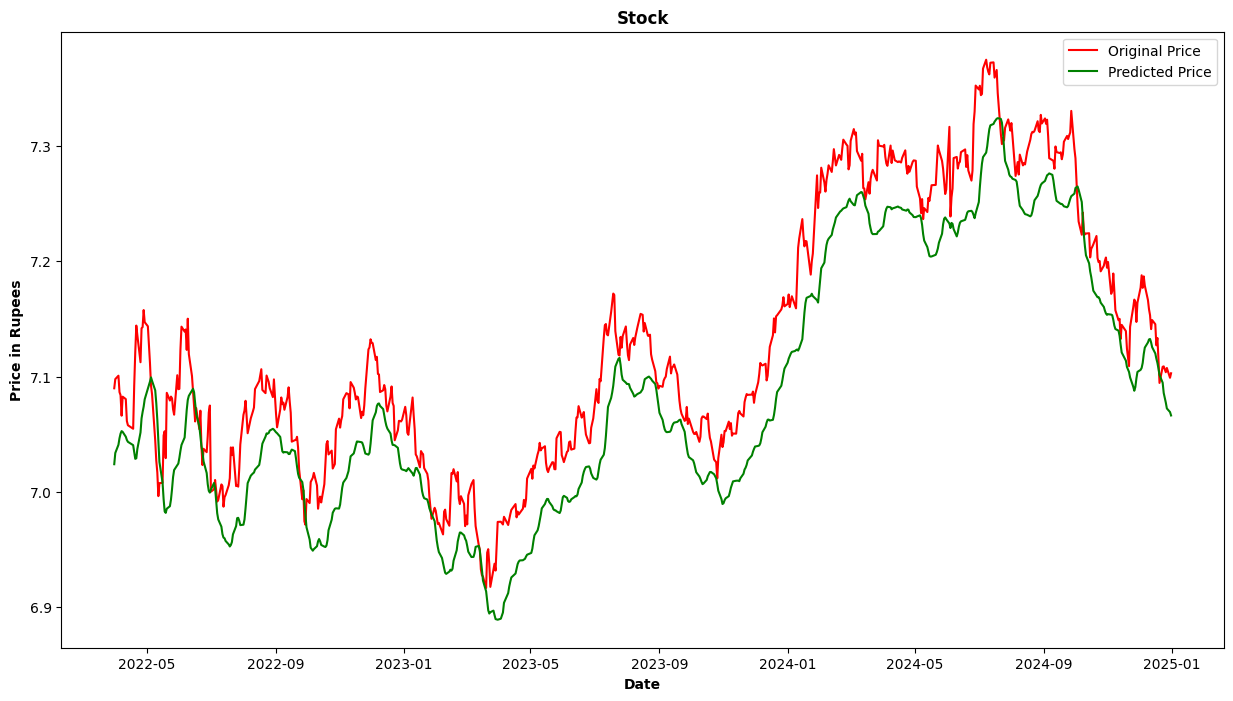

In [ ]:
# Plotting the predictied price wrt original price

plt.figure(figsize=(15,8))
plt.plot(final_test.close, label='Original Price', color='red')
plt.plot(final_test.test, label='Predicted Price', color='green')
plt.title('Stock', fontweight='bold',)
plt.ylabel('Price in Rupees', fontweight='bold')
plt.xlabel('Date', fontweight='bold')
plt.legend()
plt.show()

### For NIFTY-50 index fund


In [ ]:
stock_ticker = '^NSEI'
df = pd.DataFrame(yf.download(stock_ticker, start='2015-01-01', end='2025-01-01'))

df.reset_index(inplace=True)
df = df[['Date', 'Close']]
df.rename(columns={'Date':'date', 'Close':'close'}, inplace=True)

[*********************100%***********************]  1 of 1 completed


In [ ]:
df2 = pd.DataFrame(np.log(df['close']))
df2['date'] = pd.to_datetime(df['date']).dt.date

df2.set_index('date', inplace=True)
df2.rename(columns={'^NSEI':'close'}, inplace=True)
df2

Ticker,close
date,
2015-01-02,9.035445
2015-01-05,9.033412
2015-01-06,9.002990
2015-01-07,8.999879
2015-01-08,9.016100
...,...
2024-12-24,10.074396
2024-12-26,10.075346
2024-12-27,10.078004


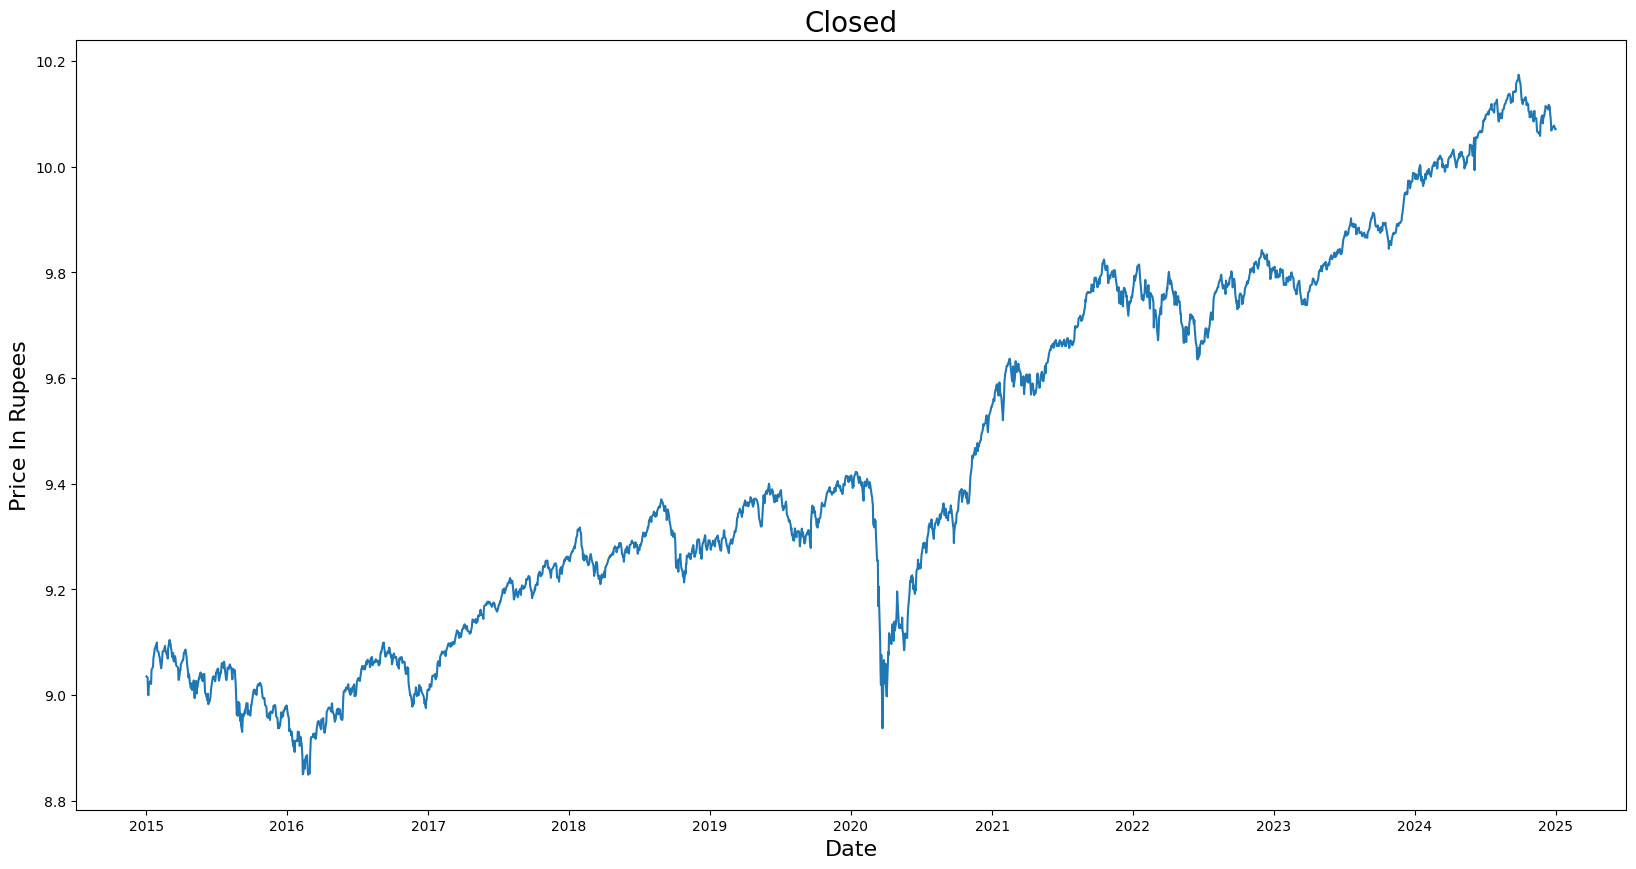

In [ ]:
plt.figure(figsize=(20,10))
plt.plot(df2['close'])
plt.title('Closed', fontsize=20)
plt.ylabel('Price In Rupees', fontsize=16)
plt.xlabel('Date', fontsize=16)
plt.show()

In [ ]:
def check_stationary(data):
    result = adfuller(data)
    print('ADF Statistic:', result[0])
    print('p-value:', result[1])
    if result[1] <= 0.05:
        print('The data is stationary.')
    else:
        print('The data is not stationary.')

check_stationary(df2.close)

first_diffs = df2.close - df2.close.shift(1)

df2['FirstDifference'] = first_diffs
df2.dropna(inplace=True)

check_stationary(df2.FirstDifference)

ADF Statistic: -0.16778877293400962
p-value: 0.942253775510871
The data is not stationary.
ADF Statistic: -13.624903927228129
p-value: 1.7677609625910624e-25
The data is stationary.


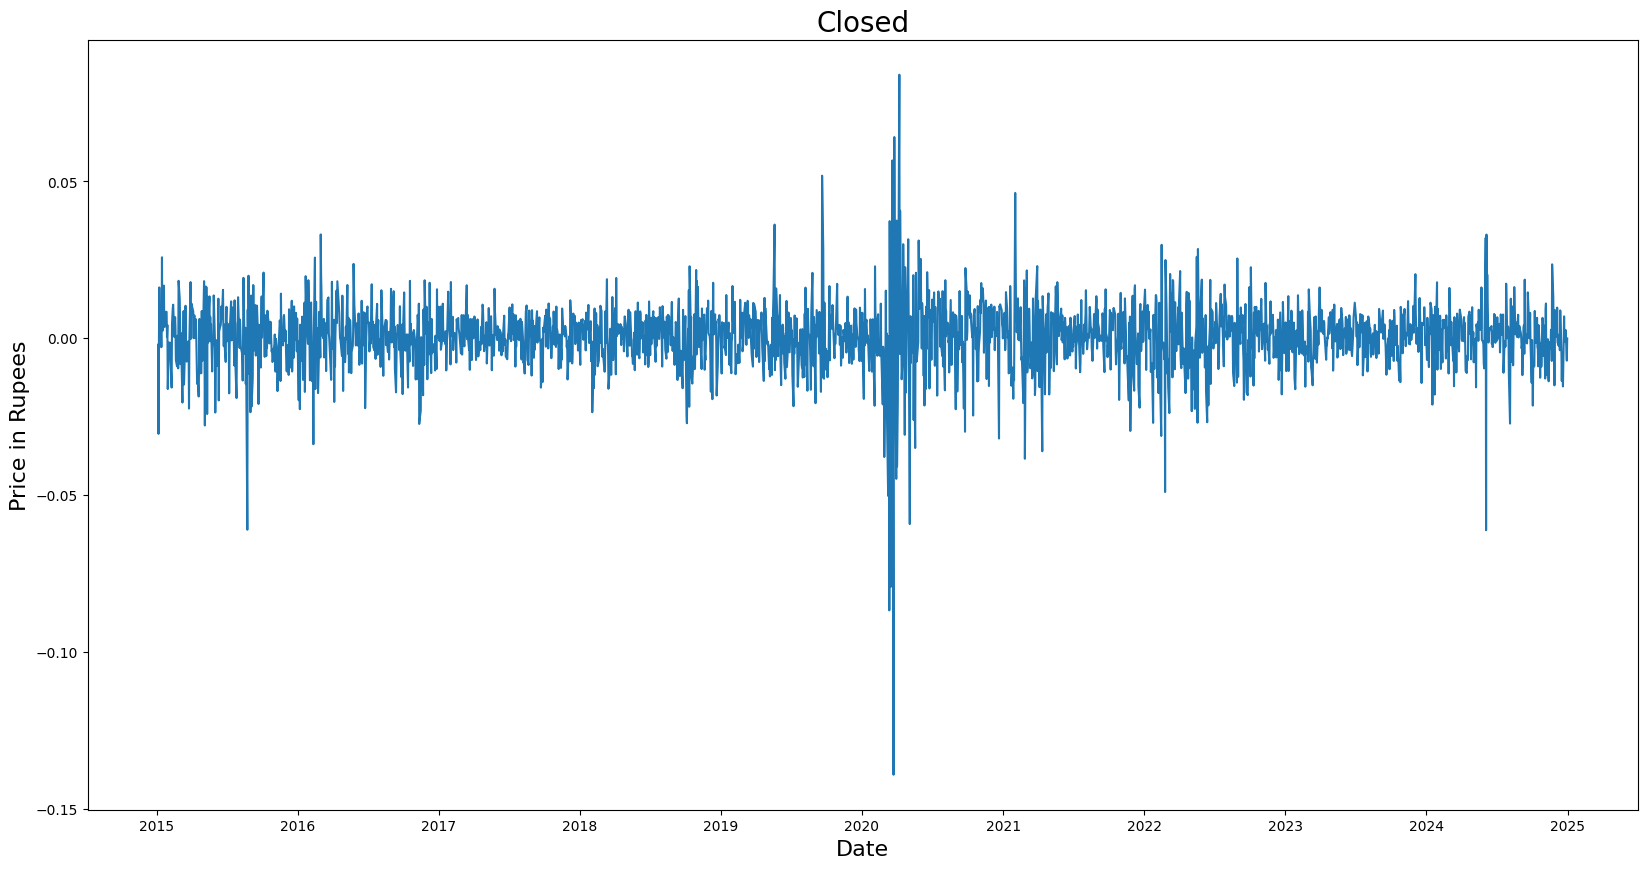

In [ ]:
plt.figure(figsize=(20,10))
plt.plot(df2.FirstDifference)
plt.title('Closed', fontsize=20)
plt.ylabel('Price in Rupees', fontsize=16)
plt.xlabel('Date', fontsize=16)
plt.show()

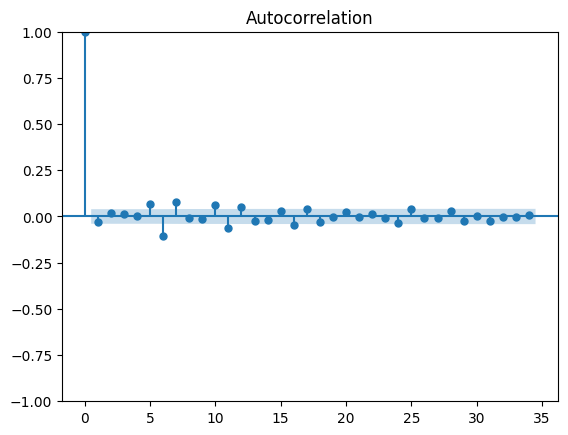

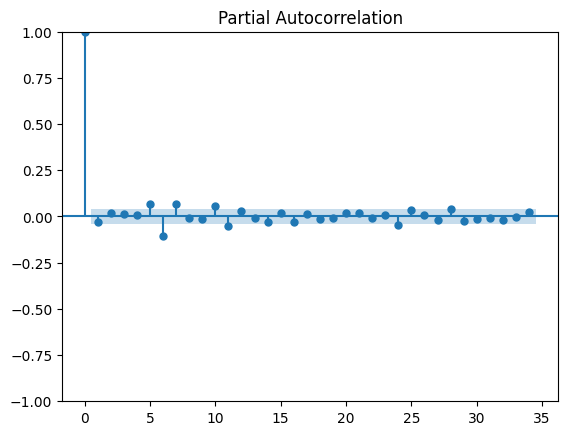

In [ ]:
# Plotting ACF plot to choose value for MA

plot_acf(df2.FirstDifference)
plt.show()

# Plotting PACF plot to choose value for AR

plot_pacf(df2.FirstDifference)
plt.show()

In [ ]:
# Creating the ARIMA model and fitting the values

model = ARIMA(df2.FirstDifference.dropna(), order=(1,1,0))
result = model.fit()

fvalues = result.fittedvalues
result.summary()

residual = result.resid
residual = residual.cumsum()

In [ ]:

a = df2.close - df2.FirstDifference
diff_results = residual + residual.shift(-1)
diff_results = diff_results + a

In [ ]:
df1 = diff_results
df1.dropna(inplace=True)

# Normalizing the data

scaler = MinMaxScaler(feature_range=(0,1))
df1 = scaler.fit_transform(np.array(df1).reshape(-1,1))

In [ ]:
# Defining the train and test data size

training_size=int(len(df1)*0.70)
test_size=len(df1)-training_size
train_data,test_data=df1[:training_size],df1[training_size:]

In [ ]:
def create_dataset(dataset, time_step=60):
	dataX, dataY = [], []
	for i in range(len(dataset)-time_step-1):
		a = dataset[i:(i+time_step)]
		dataX.append(a)
		dataY.append(dataset[i + time_step])
	return np.array(dataX), np.array(dataY)

time_step = 60
X_train, y_train = create_dataset(train_data, time_step)
X_test, y_test = create_dataset(test_data, time_step)

In [ ]:
X_train =X_train.reshape(X_train.shape[0],X_train.shape[1] , 1)
X_test = X_test.reshape(X_test.shape[0],X_test.shape[1] , 1)

len(X_train), len(y_train), len(X_test), len(y_test)

(1658, 1658, 677, 677)

In [ ]:
# Creating LSTM model

model=Sequential()
model.add(LSTM(64, input_shape=(X_train.shape[1],1)))
model.add(Dropout(0.3))
model.add(Dense(25))
model.add(Dense(1))
model.compile(loss='mean_squared_error',optimizer='adam', metrics=['accuracy'])

In [ ]:
# Summary for LSTM model

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ lstm_1 (LSTM)                        │ (None, 64)                  │          16,896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 64)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 25)                  │           1,625 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 1)                   │              26 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 18,547 (72.45 KB)

 Trainable params: 18,547 (72.45 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
model.fit(X_train,y_train,validation_data=(X_test,y_test),epochs=5,batch_size=64,verbose=1)

Epoch 1/5
26/26 ━━━━━━━━━━━━━━━━━━━━ 5s 55ms/step - accuracy: 0.0012 - loss: 0.0397 - val_accuracy: 0.0015 - val_loss: 0.0336
Epoch 2/5
26/26 ━━━━━━━━━━━━━━━━━━━━ 2s 62ms/step - accuracy: 5.0537e-04 - loss: 0.0040 - val_accuracy: 0.0015 - val_loss: 0.0038
Epoch 3/5
26/26 ━━━━━━━━━━━━━━━━━━━━ 3s 128ms/step - accuracy: 7.5249e-04 - loss: 0.0020 - val_accuracy: 0.0015 - val_loss: 1.9861e-04
Epoch 4/5
26/26 ━━━━━━━━━━━━━━━━━━━━ 4s 96ms/step - accuracy: 4.5715e-04 - loss: 0.0019 - val_accuracy: 0.0015 - val_loss: 1.8131e-04
Epoch 5/5
26/26 ━━━━━━━━━━━━━━━━━━━━ 1s 47ms/step - accuracy: 4.4677e-05 - loss: 0.0017 - val_accuracy: 0.0015 - val_loss: 3.4090e-04


In [ ]:
train_predict=model.predict(X_train)
test_predict=model.predict(X_test)

52/52 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step


In [ ]:
mape_stock = mean_absolute_percentage_error(y_test,test_predict)
rmse_stock = np.sqrt(mean_squared_error(y_test,test_predict))
mase_stock = np.mean(np.abs(y_test - test_predict)) / np.mean(np.abs(pd.DataFrame(y_test).diff().dropna()))
print(f"NIFTY - MAPE: {mape_stock}, RMSE: {rmse_stock}, MASE: {mase_stock}")

NIFTY - MAPE: 0.02047045922871622, RMSE: 0.01846358748702836, MASE: 2.8028930255213504


In [ ]:
final_test = pd.DataFrame(df2[1781:])
final_test['test'] = scaler.inverse_transform(test_predict)

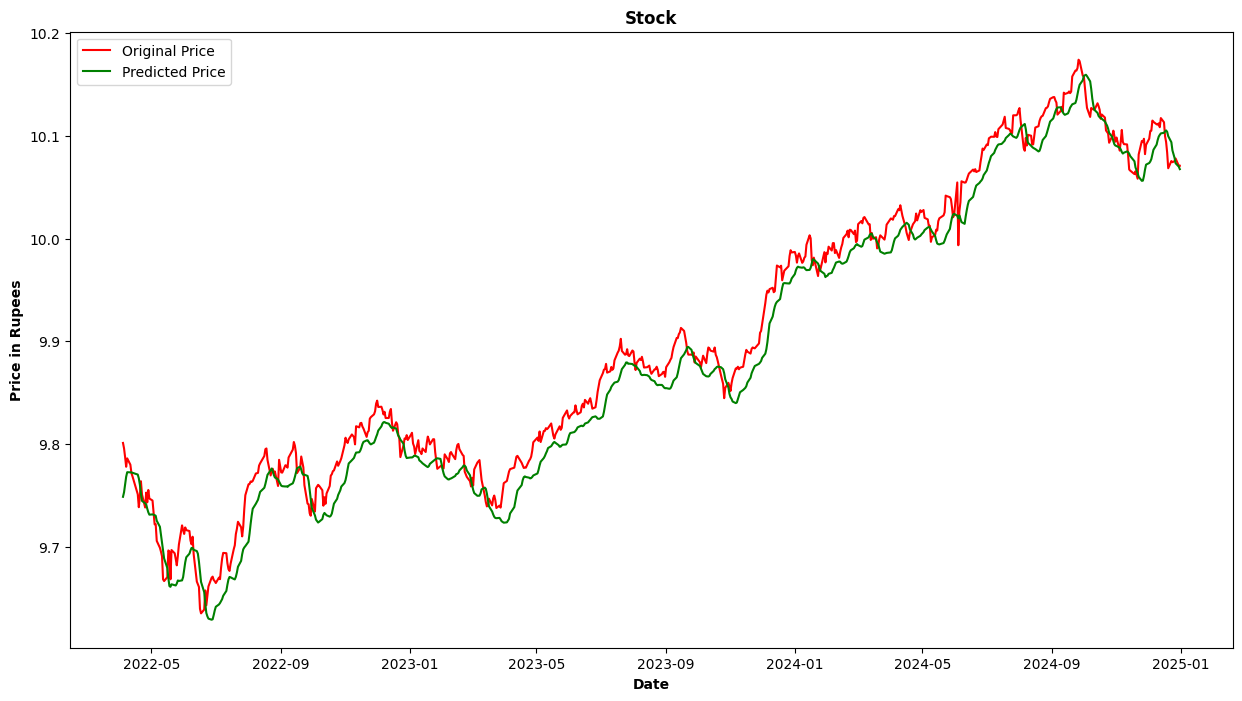

In [ ]:
# Plotting the predictied price wrt original price of test

plt.figure(figsize=(15,8))
plt.plot(final_test.close, label='Original Price', color='red')
plt.plot(final_test.test, label='Predicted Price', color='green')
plt.title('NIFTY', fontweight='bold',)
plt.ylabel('Price in Rupees', fontweight='bold')
plt.xlabel('Date', fontweight='bold')
plt.legend()
plt.show()